# Bedrohungsanalyse und Risikobewertung (TARA)

**Modul 05 · Cybersicherheit (ISO/SAE 21434)** · Notebook 2 von 5 (Deutsche Ausgabe)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/de/05_Cybersecurity_ISO21434/02_tara.ipynb)

| Niveau | Voraussetzungen | Normen |
|---|---|---|
| Fortgeschritten | [Grundlagen ISO/SAE 21434](../../05_Cybersecurity_ISO21434/01_iso21434_fundamentals.ipynb) (engl.), [G&R (HARA)](../03_Functional_Safety_ISO26262/02_hara.ipynb) | ISO/SAE 21434:2021 (Abschn. 9, 15; Anhänge E–H), ISO 26262-3:2018 |

**Autor:** Milin Patel · Hochschule Kempten · MIT-Lizenz

> **Deutsche Ausgabe.** Der Programmcode ist mit dem [englischen Original](../../05_Cybersecurity_ISO21434/02_tara.ipynb) identisch; Diagramme, Tabellen und Textausgaben erscheinen deshalb auf Englisch.

## Lernziele

Nach diesem Notebook können Sie:
- alle sieben TARA-Schritte aus Abschnitt 15 der ISO/SAE 21434 für eine wahrnehmungsbasierte AEB-Funktion in der Reihenfolge der Norm durchführen;
- Bedrohungsszenarien als *Asset + Cybersicherheitseigenschaft + Ursache* formulieren und mit Schadensszenarien verknüpfen;
- Angriffspfade aufbauen, sie aggregieren (UND/ODER) und die Angriffsdurchführbarkeit nach dem Ansatz des Angriffspotenzials bewerten;
- Risikowerte, Behandlungsentscheidungen, Cybersicherheitsziele bzw. Cybersecurity Claims und CAL **programmatisch** ableiten, sodass jede Zahl rückverfolgbar ist;
- die TARA mit der G&R aus Modul 03 verbinden (Safety-Security-Co-Engineering), einschließlich der zeitlichen Prüfung von Security-Maßnahmen gegen das FTTI.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display

pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 160)
OKABE_ITO = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#000000']
rng = np.random.default_rng(42)
print('Setup complete.')

Setup complete.


## 1. Einführung in die TARA

Die **TARA (Threat Analysis and Risk Assessment, Bedrohungsanalyse und Risikobewertung)** ist das Gegenstück der Cybersicherheit zur G&R (HARA) nach ISO 26262. Beide sind analog, aber nicht gleichwertig: Eine TARA betrachtet *absichtliche* Angriffe und bewertet ihre *Durchführbarkeit*; eine G&R betrachtet *Fehlfunktionen* und bewertet Häufigkeit und Kontrollierbarkeit.

Die TARA-Methoden sind in **Abschnitt 15** definiert und werden in der Konzeptphase (Abschnitt 9), während der Produktentwicklung (Abschnitt 10) sowie immer dann angewendet, wenn neue Informationen vorliegen (Abschnitt 8, z. B. eine neu veröffentlichte Schwachstelle). Die Schritte in der Reihenfolge der Norm:

1. **Identifikation der Assets und Schadensszenarien** (15.3)
2. **Identifikation der Bedrohungsszenarien** (15.4)
3. **Auswirkungsbewertung** (Impact Rating, 15.5)
4. **Angriffspfadanalyse** (15.6)
5. **Bewertung der Angriffsdurchführbarkeit** (15.7)
6. **Bestimmung des Risikowerts** (15.8)
7. **Entscheidung zur Risikobehandlung** (15.9) → Cybersicherheitsziele (Abschnitt 9.4) oder Cybersecurity Claims

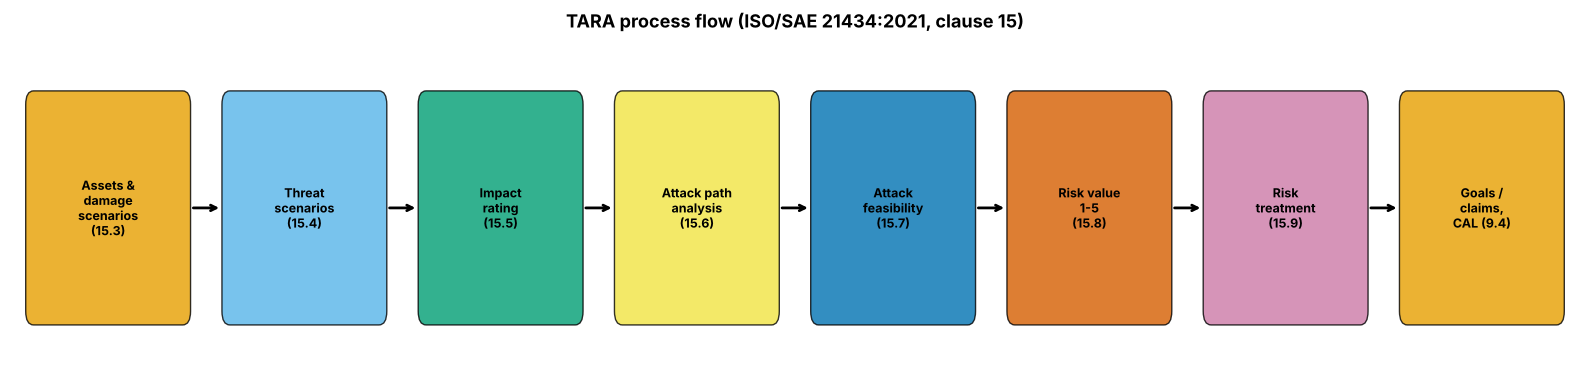

--- TARA steps (text summary) ---
  1. Assets & damage scenarios (15.3)
  2. Threat scenarios (15.4)
  3. Impact rating (15.5)
  4. Attack path analysis (15.6)
  5. Attack feasibility (15.7)
  6. Risk value 1-5 (15.8)
  7. Risk treatment (15.9)
  8. Goals / claims, CAL (9.4)


In [2]:
def visualize_tara_process():
    """TARA process flow in the order of ISO/SAE 21434 clause 15."""
    steps = ['Assets &\ndamage\nscenarios\n(15.3)', 'Threat\nscenarios\n(15.4)', 'Impact\nrating\n(15.5)',
             'Attack path\nanalysis\n(15.6)', 'Attack\nfeasibility\n(15.7)', 'Risk value\n1-5\n(15.8)',
             'Risk\ntreatment\n(15.9)', 'Goals /\nclaims,\nCAL (9.4)']
    fig, ax = plt.subplots(figsize=(16, 4))
    xs = np.linspace(0.5, 7.5, len(steps))
    colours = [OKABE_ITO[i % 7] for i in range(len(steps))]
    for i, (label, x) in enumerate(zip(steps, xs)):
        ax.add_patch(FancyBboxPatch((x - 0.38, 0.2), 0.76, 0.6, boxstyle='round,pad=0.04',
                                    facecolor=colours[i], edgecolor='black', alpha=0.8))
        ax.text(x, 0.5, label, ha='center', va='center', fontsize=9, fontweight='bold')
        if i < len(steps) - 1:
            ax.annotate('', xy=(xs[i + 1] - 0.42, 0.5), xytext=(x + 0.42, 0.5), arrowprops=dict(arrowstyle='->', lw=2))
    ax.set_xlim(0, 8); ax.set_ylim(0, 1); ax.axis('off')
    ax.set_title('TARA process flow (ISO/SAE 21434:2021, clause 15)', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()
    print('--- TARA steps (text summary) ---')
    for i, s in enumerate(steps, 1):
        print(f'  {i}. ' + s.replace(chr(10), ' '))

visualize_tara_process()

## 2. Definition der Betrachtungseinheit und Schnittstelle zur Safety

ISO/SAE 21434 (Abschn. 9.3) und ISO 26262-3 (Abschn. 5) beginnen beide mit einer **Definition der Betrachtungseinheit**. Beide Analysen sollten sich eine gemeinsame Definition teilen. Betrachtungseinheit ist hier der in der G&R von Modul 03 analysierte **Notbremsassistent (AEB)** mit seiner Wahrnehmungskette aus Kamera und Radar. Das Wahrnehmungs-Steuergerät fusioniert Kamera- und Radardetektionen und sendet eine Objektliste bzw. Bremsanforderung über CAN-FD an das Bremsen-Steuergerät.

Die **Sicherheitsziele** der G&R werden zu Eingangsgrößen der TARA: Die Verletzung eines Sicherheitsziels ist ein *sicherheitsbezogenes Schadensszenario*. Die S/E/C-Werte und FTTI unten stammen aus der G&R in [Modul 03, Notebook 02](../03_Functional_Safety_ISO26262/02_hara.ipynb): je Sicherheitsziel das gefährliche Ereignis, das seinen ASIL bestimmt (SG-01: HE-03; SG-02: HE-02, das höhere aus HE-01 und HE-02, da der ASIL eines Ziels das Maximum über die abgedeckten gefährlichen Ereignisse ist). Der ASIL wird mit Tabelle 4 der ISO 26262-3:2018 berechnet, derselben Funktion wie `avsafety.iso26262.determine_asil`.

> **Illustrative Daten:** Die Angaben zur Betrachtungseinheit sind vereinfacht; die S/E/C-Klassen und FTTI-Werte sind die illustrativen Lehrwerte der G&R aus Modul 03, nicht die eines realen Produkts.

In [3]:
item = {
    'Item': 'AEB function (camera + radar perception -> brake request), same item as the HARA in Module 03',
    'Boundary (in)': ['Front camera', 'Front radar', 'Perception ECU (DNN detector, fusion, AEB logic)',
                      'Perception-ECU software, model weights, calibration data', 'CAN-FD link perception ECU -> brake ECU'],
    'Boundary (out, interfaces)': ['Brake ECU (actuation)', 'Central gateway (diagnostics, OTA client)',
                                   'Telematics unit (cellular)', 'OEM backend (OTA, event-clip upload)'],
    'Operating modes': ['Active', 'Degraded (driver warned, AEB unavailable)', 'Off / diagnostic session'],
}
for k, v in item.items():
    print(f'{k}:')
    for x in (v if isinstance(v, list) else [v]):
        print(f'  - {x}')

# ISO 26262-3:2018 Table 4 (same as avsafety.iso26262.ASIL_TABLE): ASIL_TABLE[S][E] -> (C1, C2, C3)
ASIL_TABLE = {
    'S1': {'E1': ('QM', 'QM', 'QM'), 'E2': ('QM', 'QM', 'QM'), 'E3': ('QM', 'QM', 'A'), 'E4': ('QM', 'A', 'B')},
    'S2': {'E1': ('QM', 'QM', 'QM'), 'E2': ('QM', 'QM', 'A'), 'E3': ('QM', 'A', 'B'), 'E4': ('A', 'B', 'C')},
    'S3': {'E1': ('QM', 'QM', 'A'), 'E2': ('QM', 'A', 'B'), 'E3': ('A', 'B', 'C'), 'E4': ('B', 'C', 'D')},
}
def determine_asil(s, e, c):
    if 'S0' in s or 'E0' in e or 'C0' in c:
        return 'QM'
    return ASIL_TABLE[s][e][int(c[1]) - 1]

safety_goals = pd.DataFrame([
    # S/E/C of the worst-case hazardous event per goal (HARA, Module 03): SG-01 <- HE-03, SG-02 <- HE-02
    ('SG-01', 'Avoid unintended AEB deceleration', 'S3', 'E4', 'C3', 300),
    ('SG-02', 'Avoid omission of AEB deceleration when a collision with a pedestrian or a stationary vehicle is imminent', 'S3', 'E3', 'C2', 500),
], columns=['SG', 'Safety goal', 'S', 'E', 'C', 'FTTI_ms'])
safety_goals['ASIL'] = [determine_asil(r.S, r.E, r.C) for r in safety_goals.itertuples()]
print()
display(safety_goals)
print('--- Safety goals (text summary) ---')
for r in safety_goals.to_dict('records'):
    print(f"  {r['SG']}: {r['Safety goal']} | {r['S']}/{r['E']}/{r['C']} -> ASIL {r['ASIL']} | FTTI {r['FTTI_ms']} ms (illustrative)")

Item:
  - AEB function (camera + radar perception -> brake request), same item as the HARA in Module 03
Boundary (in):
  - Front camera
  - Front radar
  - Perception ECU (DNN detector, fusion, AEB logic)
  - Perception-ECU software, model weights, calibration data
  - CAN-FD link perception ECU -> brake ECU
Boundary (out, interfaces):
  - Brake ECU (actuation)
  - Central gateway (diagnostics, OTA client)
  - Telematics unit (cellular)
  - OEM backend (OTA, event-clip upload)
Operating modes:
  - Active
  - Degraded (driver warned, AEB unavailable)
  - Off / diagnostic session



,SG,Safety goal,S,E,C,FTTI_ms,ASIL
0,SG-01,Avoid unintended AEB deceleration,S3,E4,C3,300,D
1,SG-02,Avoid omission of AEB deceleration when a collision with a pedestrian or a s...,S3,E3,C2,500,B


--- Safety goals (text summary) ---
  SG-01: Avoid unintended AEB deceleration | S3/E4/C3 -> ASIL D | FTTI 300 ms (illustrative)
  SG-02: Avoid omission of AEB deceleration when a collision with a pedestrian or a stationary vehicle is imminent | S3/E3/C2 -> ASIL B | FTTI 500 ms (illustrative)


## 3. Bewertungstabellen

Die Tabellen sind die informativen Beispiele der ISO/SAE 21434 (Anhang G Angriffspotenzial, Anhang H Risikomatrix, Anhang E CAL), genau wie in [Notebook 1](../../05_Cybersecurity_ISO21434/01_iso21434_fundamentals.ipynb) (engl.) eingeführt. Sie sind identisch mit `avsafety.iso21434` in diesem Repository.

**Aggregation von Angriffspfaden.** Die Norm verlangt Angriffspfade, schreibt aber nicht vor, wie die Schritte zu kombinieren sind. Dieses Notebook verwendet eine verbreitete, konservative Konvention:
- **UND** (alle Schritte eines Pfades sind nötig): Je Faktor wird das **Maximum** über die Schritte genommen. Der Angreifer muss in jeder Dimension den schwierigsten Schritt beherrschen. Das Maximum der benötigten Zeit *unterschätzt* die Gesamtzeit aufeinanderfolgender Schritte; es ist also eine im Sinne der Durchführbarkeit konservative Vereinfachung.
- **ODER** (alternative Pfade): Das Bedrohungsszenario ist so durchführbar wie sein **am leichtesten durchführbarer** Pfad, d. h. der Pfad mit dem kleinsten Angriffspotenzial.

Dokumentieren Sie die gewählte Konvention in der Methodenbeschreibung der TARA.

In [4]:
IMPACT_LEVELS = ['Negligible', 'Moderate', 'Major', 'Severe']
FEASIBILITY_LEVELS = ['Very Low', 'Low', 'Medium', 'High']
FACTORS = {
    'elapsed_time': {'<=1 day': 0, '<=1 week': 1, '<=1 month': 4, '<=6 months': 17, '>6 months': 19},
    'expertise':    {'layman': 0, 'proficient': 3, 'expert': 6, 'multiple experts': 8},
    'knowledge':    {'public': 0, 'restricted': 3, 'confidential': 7, 'strictly confidential': 11},
    'window':       {'unlimited': 0, 'easy': 1, 'moderate': 4, 'difficult': 10},
    'equipment':    {'standard': 0, 'specialized': 4, 'bespoke': 7, 'multiple bespoke': 9},
}
VECTORS = ['Physical', 'Local', 'Adjacent', 'Network']        # ordered from least to most remote
FEASIBILITY_FROM_VECTOR = {'Network': 'High', 'Adjacent': 'Medium', 'Local': 'Low', 'Physical': 'Very Low'}
RISK_MATRIX = {
    'Severe':     {'Very Low': 2, 'Low': 3, 'Medium': 4, 'High': 5},
    'Major':      {'Very Low': 1, 'Low': 2, 'Medium': 3, 'High': 4},
    'Moderate':   {'Very Low': 1, 'Low': 2, 'Medium': 2, 'High': 3},
    'Negligible': {'Very Low': 1, 'Low': 1, 'Medium': 1, 'High': 1},
}
CAL_TABLE = {
    'Severe':   {'Physical': 2, 'Local': 3, 'Adjacent': 4, 'Network': 4},
    'Major':    {'Physical': 1, 'Local': 2, 'Adjacent': 3, 'Network': 4},
    'Moderate': {'Physical': 1, 'Local': 1, 'Adjacent': 2, 'Network': 3},
}

def feasibility_from_potential(ap):
    return 'High' if ap <= 13 else 'Medium' if ap <= 19 else 'Low' if ap <= 24 else 'Very Low'

def determine_cal(impact, vector):
    return None if impact == 'Negligible' else CAL_TABLE[impact][vector]

def step(action, elapsed_time, expertise, knowledge, window, equipment, vector=None):
    """One attack step; factor values are validated against the Annex G tables."""
    s = {'action': action, 'vector': vector}
    for name, label in zip(FACTORS, (elapsed_time, expertise, knowledge, window, equipment)):
        if label not in FACTORS[name]:
            raise ValueError(f'invalid {name}: {label!r}')
        s[name] = FACTORS[name][label]
    return s

def aggregate_and(steps, floors=None):
    """AND aggregation: factor-wise maximum over steps (optionally raised to control 'floors')."""
    agg = {f: max(s[f] for s in steps) for f in FACTORS}
    for f, label in (floors or {}).items():
        agg[f] = max(agg[f], FACTORS[f][label])
    agg['attack_potential'] = sum(agg[f] for f in FACTORS)
    agg['feasibility'] = feasibility_from_potential(agg['attack_potential'])
    agg['vector'] = steps[0]['vector']  # the entry point determines the attack vector
    return agg

assert feasibility_from_potential(13) == 'High' and feasibility_from_potential(25) == 'Very Low'
assert determine_cal('Severe', 'Network') == 4 and determine_cal('Negligible', 'Network') is None
print('Rating tables and aggregation helpers ready.')

Rating tables and aggregation helpers ready.


## 4. Schritt 1 – Assets und Schadensszenarien (15.3)

Ein **Asset** (Schutzobjekt) ist ein Objekt, das einen Wert hat und dessen Beeinträchtigung in einer oder mehreren **Cybersicherheitseigenschaften** (Vertraulichkeit, Integrität, Verfügbarkeit; Organisationen ergänzen oft Authentizität, Autorisierung, Nichtabstreitbarkeit) zu einem Schadensszenario führen kann. Ein **Schadensszenario** beschreibt die nachteilige Folge für einen Verkehrsteilnehmer. Es wird später in den SFOP-Kategorien (Safety, Financial, Operational, Privacy) bewertet.

| Kategorie | Beispiele |
|---|---|
| Daten | Sensordatenströme, Objektliste, Kalibrierparameter, aufgezeichnete Clips |
| Software | DNN-Gewichte, Firmware |
| Kommunikation | CAN-FD-Botschaften, V2X, OTA-Kanal |
| Funktion | Fußgängererkennung, Bremsanforderung |

Sicherheitsbezogene Schadensszenarien entsprechen Verletzungen der Sicherheitsziele aus der G&R; die Verknüpfung mit SG-01/SG-02 wird deshalb ausdrücklich festgehalten.

In [5]:
assets = pd.DataFrame([
    ('A-01', 'Camera video stream (camera -> perception ECU)', 'Data', ['Integrity', 'Availability']),
    ('A-02', 'Perception DNN weights and configuration', 'Software', ['Integrity']),
    ('A-03', 'Object list / brake request on CAN-FD', 'Communication', ['Integrity', 'Availability']),
    ('A-04', 'Perception-ECU firmware', 'Software', ['Integrity']),
    ('A-05', 'Camera calibration parameters (extrinsics)', 'Data', ['Integrity']),
    ('A-06', 'Recorded AEB event clips (camera images)', 'Data', ['Confidentiality']),
], columns=['Asset', 'Name', 'Category', 'Properties'])

# Damage scenarios: impact per SFOP category from the road user's perspective (0..3 = Negligible..Severe)
# Safety impact reuses the HARA severity of the same harm: S3 -> Severe (ISO/SAE 21434 Annex F)
damage = pd.DataFrame([
    ('DS-01', 'Unintended emergency braking in following traffic leads to a rear-end collision', 3, 1, 1, 0, 'SG-01'),
    ('DS-02', 'No or late emergency braking for a pedestrian in the path leads to a fatal collision', 3, 2, 2, 0, 'SG-02'),
    ('DS-03', 'AEB unavailable (degraded mode, driver warned)', 0, 0, 2, 0, '-'),
    ('DS-04', 'Recorded images of identifiable pedestrians/occupants are disclosed', 0, 1, 0, 2, '-'),
], columns=['DS', 'Damage scenario', 'Safety', 'Financial', 'Operational', 'Privacy', 'Safety goal'])
for c in ['Safety', 'Financial', 'Operational', 'Privacy']:
    damage[c + '_label'] = damage[c].map(lambda v: IMPACT_LEVELS[v])
damage['Impact'] = damage[['Safety', 'Financial', 'Operational', 'Privacy']].max(axis=1).map(lambda v: IMPACT_LEVELS[v])

display(assets)
display(damage[['DS', 'Damage scenario', 'Safety_label', 'Financial_label', 'Operational_label', 'Privacy_label', 'Impact', 'Safety goal']])
print('--- Damage scenarios (text summary) ---')
for r in damage.to_dict('records'):
    print(f"  {r['DS']}: {r['Damage scenario']} | impact {r['Impact']}" + (f" | violates {r['Safety goal']}" if r['Safety goal'] != '-' else ''))

,Asset,Name,Category,Properties
0,A-01,Camera video stream (camera -> perception ECU),Data,"[Integrity, Availability]"
1,A-02,Perception DNN weights and configuration,Software,[Integrity]
2,A-03,Object list / brake request on CAN-FD,Communication,"[Integrity, Availability]"
3,A-04,Perception-ECU firmware,Software,[Integrity]
4,A-05,Camera calibration parameters (extrinsics),Data,[Integrity]
5,A-06,Recorded AEB event clips (camera images),Data,[Confidentiality]


,DS,Damage scenario,Safety_label,Financial_label,Operational_label,Privacy_label,Impact,Safety goal
0,DS-01,Unintended emergency braking in following traffic leads to a rear-end collision,Severe,Moderate,Moderate,Negligible,Severe,SG-01
1,DS-02,No or late emergency braking for a pedestrian in the path leads to a fatal c...,Severe,Major,Major,Negligible,Severe,SG-02
2,DS-03,"AEB unavailable (degraded mode, driver warned)",Negligible,Negligible,Major,Negligible,Major,-
3,DS-04,Recorded images of identifiable pedestrians/occupants are disclosed,Negligible,Moderate,Negligible,Major,Major,-


--- Damage scenarios (text summary) ---
  DS-01: Unintended emergency braking in following traffic leads to a rear-end collision | impact Severe | violates SG-01
  DS-02: No or late emergency braking for a pedestrian in the path leads to a fatal collision | impact Severe | violates SG-02
  DS-03: AEB unavailable (degraded mode, driver warned) | impact Major
  DS-04: Recorded images of identifiable pedestrians/occupants are disclosed | impact Major


## 5. Schritt 2 – Bedrohungsszenarien (15.4)

Ein Bedrohungsszenario benennt das **Asset**, die beeinträchtigte **Cybersicherheitseigenschaft** und die **Ursache** und verweist auf ein oder mehrere Schadensszenarien. Beispiel: *„Das Fälschen (Spoofing) von Objektlisten-Botschaften auf CAN-FD führt zum Verlust der Integrität der Bremsanforderung, was DS-01 verursachen kann.“*

STRIDE ist eine nützliche Heuristik, um Ursachen zu sammeln. Jede STRIDE-Kategorie bedroht eine Eigenschaft: Spoofing (Vortäuschen einer Identität) → Authentizität, Tampering (Manipulation) → Integrität, Repudiation (Abstreiten) → Nichtabstreitbarkeit, Information Disclosure (Offenlegung) → Vertraulichkeit, Denial of Service → Verfügbarkeit, Elevation of Privilege (Rechteausweitung) → Autorisierung.

**Hinweis zur Abgrenzung.** TS-03 (adversarieller Patch) und TS-04 (Blendung) greifen die *Umgebung* vor dem Sensor an, nicht die Datenverbindung. Sie sind Bedrohungsszenarien der Cybersicherheit, weil sie absichtlich herbeigeführt werden. Dieselben Schwächen der Wahrnehmung müssen auch nach ISO 21448 (auslösende Bedingungen) und ISO/PAS 8800 (Robustheit von ML) analysiert werden; siehe [Adversarielle Angriffe](../../02_Failures_and_Robustness/04_adversarial_attacks.ipynb) (engl.).

In [6]:
STRIDE_PROPERTY = {'Spoofing': 'Integrity', 'Tampering': 'Integrity', 'Information disclosure': 'Confidentiality',
                   'Denial of service': 'Availability'}   # authenticity is treated as part of integrity here

threats = pd.DataFrame([
    ('TS-01', 'A-03', 'Spoofing', 'forged object-list/brake-request frames injected on CAN-FD', ['DS-01']),
    ('TS-02', 'A-02', 'Tampering', 'manipulated DNN weights installed through a malicious software update', ['DS-02']),
    ('TS-03', 'A-03', 'Tampering', 'a physical adversarial patch that suppresses pedestrian detections', ['DS-02']),
    ('TS-04', 'A-01', 'Denial of service', 'dazzling of the camera with a high-power light source', ['DS-02', 'DS-03']),
    ('TS-05', 'A-05', 'Tampering', 'calibration parameters rewritten via diagnostic services', ['DS-02']),
    ('TS-06', 'A-06', 'Information disclosure', 'event clips read out via diagnostic services', ['DS-04']),
    ('TS-07', 'A-03', 'Denial of service', 'flooding of the CAN-FD segment with high-priority frames', ['DS-03']),
], columns=['TS', 'Asset', 'STRIDE', 'Cause', 'Damage scenarios'])

asset_name = dict(zip(assets.Asset, assets.Name))
asset_props = dict(zip(assets.Asset, assets.Properties))
threats['Property'] = threats.STRIDE.map(STRIDE_PROPERTY)
# Consistency checks: the threatened property must be a property of the asset, and DS references must exist
for r in threats.to_dict('records'):
    assert r['Property'] in asset_props[r['Asset']], f"{r['TS']}: {r['Property']} not a property of {r['Asset']}"
    assert set(r['Damage scenarios']) <= set(damage.DS), f"{r['TS']}: unknown damage scenario"
threats['Threat scenario'] = [f'Loss of {r["Property"].lower()} of "{asset_name[r["Asset"]]}" caused by {r["Cause"]}'
                              for r in threats.to_dict('records')]
display(threats[['TS', 'Asset', 'STRIDE', 'Property', 'Threat scenario', 'Damage scenarios']])
print('--- Threat scenarios (text summary) ---')
for r in threats.to_dict('records'):
    print(f"  {r['TS']}: {r['Threat scenario']} -> {', '.join(r['Damage scenarios'])}")

,TS,Asset,STRIDE,Property,Threat scenario,Damage scenarios
0,TS-01,A-03,Spoofing,Integrity,"Loss of integrity of ""Object list / brake request on CAN-FD"" caused by forge...",[DS-01]
1,TS-02,A-02,Tampering,Integrity,"Loss of integrity of ""Perception DNN weights and configuration"" caused by ma...",[DS-02]
2,TS-03,A-03,Tampering,Integrity,"Loss of integrity of ""Object list / brake request on CAN-FD"" caused by a phy...",[DS-02]
3,TS-04,A-01,Denial of service,Availability,"Loss of availability of ""Camera video stream (camera -> perception ECU)"" cau...","[DS-02, DS-03]"
4,TS-05,A-05,Tampering,Integrity,"Loss of integrity of ""Camera calibration parameters (extrinsics)"" caused by ...",[DS-02]
5,TS-06,A-06,Information disclosure,Confidentiality,"Loss of confidentiality of ""Recorded AEB event clips (camera images)"" caused...",[DS-04]
6,TS-07,A-03,Denial of service,Availability,"Loss of availability of ""Object list / brake request on CAN-FD"" caused by fl...",[DS-03]


--- Threat scenarios (text summary) ---
  TS-01: Loss of integrity of "Object list / brake request on CAN-FD" caused by forged object-list/brake-request frames injected on CAN-FD -> DS-01
  TS-02: Loss of integrity of "Perception DNN weights and configuration" caused by manipulated DNN weights installed through a malicious software update -> DS-02
  TS-03: Loss of integrity of "Object list / brake request on CAN-FD" caused by a physical adversarial patch that suppresses pedestrian detections -> DS-02
  TS-04: Loss of availability of "Camera video stream (camera -> perception ECU)" caused by dazzling of the camera with a high-power light source -> DS-02, DS-03
  TS-05: Loss of integrity of "Camera calibration parameters (extrinsics)" caused by calibration parameters rewritten via diagnostic services -> DS-02
  TS-06: Loss of confidentiality of "Recorded AEB event clips (camera images)" caused by event clips read out via diagnostic services -> DS-04
  TS-07: Loss of availability of "Obje

## 6. Schritt 3 – Auswirkungsbewertung (15.5)

Die Auswirkung eines Bedrohungsszenarios ist die Auswirkung seiner Schadensszenarien. Bei mehreren verknüpften Schadensszenarien nehmen wir die ungünstigste SFOP-Einstufung; das ist konservativ. Die Auswirkung wird **vor** Berücksichtigung der Schutzmaßnahmen bewertet, die die TARA später festlegt, und aus Sicht des Verkehrsteilnehmers.

In [7]:
ds_index = damage.set_index('DS')
def impact_of(ds_list):
    sfop = ds_index.loc[ds_list, ['Safety', 'Financial', 'Operational', 'Privacy']].max(axis=0)
    return IMPACT_LEVELS[int(sfop.max())], {k: IMPACT_LEVELS[int(v)] for k, v in sfop.items()}

threats['Impact'] = [impact_of(d)[0] for d in threats['Damage scenarios']]
threats['Safety impact'] = [impact_of(d)[1]['Safety'] for d in threats['Damage scenarios']]
display(threats[['TS', 'Damage scenarios', 'Safety impact', 'Impact']])

,TS,Damage scenarios,Safety impact,Impact
0,TS-01,[DS-01],Severe,Severe
1,TS-02,[DS-02],Severe,Severe
2,TS-03,[DS-02],Severe,Severe
3,TS-04,"[DS-02, DS-03]",Severe,Severe
4,TS-05,[DS-02],Severe,Severe
5,TS-06,[DS-04],Negligible,Major
6,TS-07,[DS-03],Negligible,Major


## 7. Schritt 4 – Angriffspfadanalyse (15.6)

Jedes Bedrohungsszenario wird durch einen oder mehrere **Angriffspfade** (ODER) realisiert. Jeder Pfad ist eine Folge von **Schritten** (UND). Jeder Schritt trägt seine Faktoren des Angriffspotenzials, sodass ein Reviewer sie einzeln hinterfragen kann. Der Einstiegsschritt bestimmt den **Angriffsvektor** des Pfades.

> **Illustrative Daten:** Die Faktorwerte sind Beispiele einer Experteneinschätzung für die Lehre, keine Ergebnisse einer realen Bewertung.

In [8]:
reverse_engineer = step('Reverse-engineer seed/key algorithm from a purchased spare ECU',
                        '<=1 month', 'expert', 'restricted', 'unlimited', 'specialized', 'Local')
forge_frames = step('Craft valid-looking object-list frames (no authentication on the bus)',
                    '<=1 week', 'proficient', 'restricted', 'unlimited', 'standard')

attack_paths = {
    'TS-01': {
        'AP-01a': [step('Remote code execution on the telematics unit', '<=6 months', 'expert', 'confidential', 'unlimited', 'specialized', 'Network'),
                   step('Bypass gateway routing/filtering to reach the AEB CAN-FD segment', '<=1 month', 'expert', 'confidential', 'unlimited', 'standard'),
                   forge_frames],
        'AP-01b': [step('Splice a device into the CAN-FD wiring at the front-radar connector', '<=1 week', 'proficient', 'restricted', 'moderate', 'specialized', 'Physical'),
                   forge_frames],
    },
    'TS-02': {
        'AP-02a': [step('Compromise OEM backend and code-signing infrastructure', '>6 months', 'multiple experts', 'strictly confidential', 'easy', 'bespoke', 'Network')],
        'AP-02b': [step('Bypass secure boot and reflash via the diagnostic port', '<=6 months', 'expert', 'confidential', 'moderate', 'bespoke', 'Local')],
    },
    'TS-03': {
        'AP-03a': [step('Craft a transferable adversarial patch on a public surrogate model', '<=1 month', 'expert', 'restricted', 'unlimited', 'standard', 'Physical'),
                   step('Place the printed patch in the road environment', '<=1 day', 'layman', 'public', 'easy', 'standard')],
    },
    'TS-04': {
        'AP-04a': [step('Aim a high-power light source at the camera of an approaching vehicle', '<=1 day', 'proficient', 'public', 'moderate', 'standard', 'Physical')],
    },
    'TS-05': {
        'AP-05a': [reverse_engineer,
                   step('Connect to the target vehicle OBD-II port and write calibration DIDs', '<=1 day', 'proficient', 'restricted', 'moderate', 'specialized')],
    },
    'TS-06': {
        'AP-06a': [reverse_engineer,
                   step('Connect to the target vehicle OBD-II port and read event clips', '<=1 day', 'proficient', 'restricted', 'moderate', 'specialized')],
    },
    'TS-07': {
        'AP-07a': [step('Inject high-priority flood frames at the front-radar connector', '<=1 day', 'proficient', 'public', 'moderate', 'specialized', 'Physical')],
    },
}
assert set(attack_paths) == set(threats.TS), 'every threat scenario needs at least one attack path'

rows = []
for ts, paths in attack_paths.items():
    for ap, steps in paths.items():
        agg = aggregate_and(steps)
        rows.append({'TS': ts, 'Path': ap, 'Steps': len(steps), 'Vector': agg['vector'],
                     **{f: agg[f] for f in FACTORS}, 'Attack potential': agg['attack_potential'],
                     'Feasibility': agg['feasibility']})
paths_df = pd.DataFrame(rows)
display(paths_df)
print('--- Attack paths (text summary) ---')
for r in paths_df.to_dict('records'):
    print(f"  {r['TS']}/{r['Path']}: {r['Steps']} step(s), entry {r['Vector']}, attack potential {r['Attack potential']} -> {r['Feasibility']}")

,TS,Path,Steps,Vector,elapsed_time,expertise,knowledge,window,equipment,Attack potential,Feasibility
0,TS-01,AP-01a,3,Network,17,6,7,0,4,34,Very Low
1,TS-01,AP-01b,2,Physical,1,3,3,4,4,15,Medium
2,TS-02,AP-02a,1,Network,19,8,11,1,7,46,Very Low
3,TS-02,AP-02b,1,Local,17,6,7,4,7,41,Very Low
4,TS-03,AP-03a,2,Physical,4,6,3,1,0,14,Medium
5,TS-04,AP-04a,1,Physical,0,3,0,4,0,7,High
6,TS-05,AP-05a,2,Local,4,6,3,4,4,21,Low
7,TS-06,AP-06a,2,Local,4,6,3,4,4,21,Low
8,TS-07,AP-07a,1,Physical,0,3,0,4,4,11,High


--- Attack paths (text summary) ---
  TS-01/AP-01a: 3 step(s), entry Network, attack potential 34 -> Very Low
  TS-01/AP-01b: 2 step(s), entry Physical, attack potential 15 -> Medium
  TS-02/AP-02a: 1 step(s), entry Network, attack potential 46 -> Very Low
  TS-02/AP-02b: 1 step(s), entry Local, attack potential 41 -> Very Low
  TS-03/AP-03a: 2 step(s), entry Physical, attack potential 14 -> Medium
  TS-04/AP-04a: 1 step(s), entry Physical, attack potential 7 -> High
  TS-05/AP-05a: 2 step(s), entry Local, attack potential 21 -> Low
  TS-06/AP-06a: 2 step(s), entry Local, attack potential 21 -> Low
  TS-07/AP-07a: 1 step(s), entry Physical, attack potential 11 -> High


## 8. Schritt 5 – Bewertung der Angriffsdurchführbarkeit (15.7)

Die Durchführbarkeit eines Bedrohungsszenarios ist die seines am leichtesten durchführbaren Pfades (ODER = kleinstes Angriffspotenzial). Zum Vergleich wird auch die grobe **angriffsvektorbasierte** Bewertung (Anhang G.4) gezeigt. Für den **CAL** halten wir den *entferntesten* Vektor über alle Pfade fest. Das ist eine konservative Wahl: Ein Ziel muss gegen jeden Pfad abgesichert sein, auch gegen entfernte, die derzeit schwer sind.

In [9]:
def rate_feasibility(ts, floors=None):
    aggs = {ap: aggregate_and(steps, floors) for ap, steps in attack_paths[ts].items()}
    best = min(aggs, key=lambda ap: aggs[ap]['attack_potential'])
    most_remote = max((a['vector'] for a in aggs.values()), key=VECTORS.index)
    return best, aggs[best], most_remote

feas = []
for ts in threats.TS:
    best, agg, remote = rate_feasibility(ts)
    feas.append({'TS': ts, 'Most feasible path': best, 'Attack potential': agg['attack_potential'],
                 'Feasibility': agg['feasibility'], 'Vector (best path)': agg['vector'],
                 'Feasibility (vector method)': FEASIBILITY_FROM_VECTOR[agg['vector']], 'Most remote vector': remote})
threats = threats.drop(columns=[c for c in feas[0] if c != 'TS' and c in threats], errors='ignore').merge(pd.DataFrame(feas), on='TS')
display(threats[['TS', 'Most feasible path', 'Attack potential', 'Feasibility', 'Vector (best path)',
                 'Feasibility (vector method)', 'Most remote vector']])
n_diff = (threats['Feasibility'] != threats['Feasibility (vector method)']).sum()
print(f'The attack-vector method disagrees with the attack-potential method for {n_diff} of {len(threats)} threat scenarios.')

,TS,Most feasible path,Attack potential,Feasibility,Vector (best path),Feasibility (vector method),Most remote vector
0,TS-01,AP-01b,15,Medium,Physical,Very Low,Network
1,TS-02,AP-02b,41,Very Low,Local,Low,Network
2,TS-03,AP-03a,14,Medium,Physical,Very Low,Physical
3,TS-04,AP-04a,7,High,Physical,Very Low,Physical
4,TS-05,AP-05a,21,Low,Local,Low,Local
5,TS-06,AP-06a,21,Low,Local,Low,Local
6,TS-07,AP-07a,11,High,Physical,Very Low,Physical


The attack-vector method disagrees with the attack-potential method for 5 of 7 threat scenarios.


## 9. Schritt 6 – Bestimmung des Risikowerts (15.8)

Der Risikowert (1–5) ergibt sich aus der Beispiel-Risikomatrix (Anhang H), die Auswirkung und Angriffsdurchführbarkeit kombiniert.

,TS,Impact,Feasibility,Risk
0,TS-01,Severe,Medium,4
1,TS-02,Severe,Very Low,2
2,TS-03,Severe,Medium,4
3,TS-04,Severe,High,5
4,TS-05,Severe,Low,3
5,TS-06,Major,Low,2
6,TS-07,Major,High,4


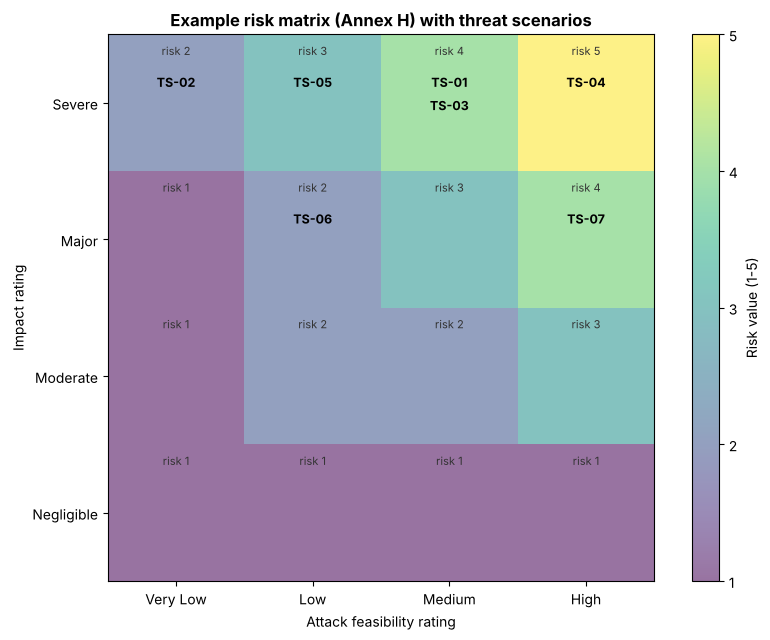

--- Risk values (text summary) ---
  TS-04: Severe x High -> risk 5
  TS-03: Severe x Medium -> risk 4
  TS-01: Severe x Medium -> risk 4
  TS-07: Major x High -> risk 4
  TS-05: Severe x Low -> risk 3
  TS-02: Severe x Very Low -> risk 2
  TS-06: Major x Low -> risk 2


In [10]:
threats['Risk'] = [RISK_MATRIX[i][f] for i, f in zip(threats['Impact'], threats['Feasibility'])]
display(threats[['TS', 'Impact', 'Feasibility', 'Risk']])

def plot_risk_matrix(df, title, risk_col='Risk', impact_col='Impact', feas_col='Feasibility'):
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    matrix = np.array([[RISK_MATRIX[i][f] for f in FEASIBILITY_LEVELS] for i in IMPACT_LEVELS])
    im = ax.imshow(matrix, cmap='viridis', vmin=1, vmax=5, origin='lower', alpha=0.55)
    for i in range(4):
        for j in range(4):
            ax.text(j, i + 0.38, f'risk {matrix[i, j]}', ha='center', va='center', fontsize=8, color='0.2')
    placed = {}
    for r in df.itertuples():
        x, y = FEASIBILITY_LEVELS.index(getattr(r, feas_col)), IMPACT_LEVELS.index(getattr(r, impact_col))
        k = placed.get((x, y), 0); placed[(x, y)] = k + 1
        ax.text(x, y + 0.15 - 0.17 * k, r.TS, ha='center', va='center', fontsize=9, fontweight='bold')
    ax.set_xticks(range(4)); ax.set_xticklabels(FEASIBILITY_LEVELS)
    ax.set_yticks(range(4)); ax.set_yticklabels(IMPACT_LEVELS)
    ax.set_xlabel('Attack feasibility rating'); ax.set_ylabel('Impact rating')
    ax.set_title(title, fontweight='bold')
    fig.colorbar(im, ax=ax, label='Risk value (1-5)', ticks=[1, 2, 3, 4, 5])
    plt.tight_layout(); plt.show()

plot_risk_matrix(threats, 'Example risk matrix (Annex H) with threat scenarios')
print('--- Risk values (text summary) ---')
for r in threats.sort_values('Risk', ascending=False).itertuples():
    print(f'  {r.TS}: {r.Impact} x {r.Feasibility} -> risk {r.Risk}')

## 10. Schritt 7 – Entscheidung zur Risikobehandlung (15.9), Ziele, Claims und CAL

Die vier Optionen sind **vermeiden** (Tätigkeit oder Funktion entfernen), **reduzieren** (Schutzmaßnahmen), **teilen** (z. B. Verträge, Versicherung) und **beibehalten** (Risiko akzeptieren). Jedes Bedrohungsszenario erhält eine Entscheidung mit Begründung.

- **Reduzieren** → ein **Cybersicherheitsziel** (Abschn. 9.4), dem ein CAL zugeordnet wird.
- **Teilen / beibehalten** → ein **Cybersecurity Claim** (begründete Aussage), der die Begründung dokumentiert.

Die Schwellen unten sind eine *beispielhafte Unternehmensrichtlinie*. ISO/SAE 21434 überlässt die Akzeptanzkriterien der Organisation, die sie dokumentieren muss.

Der CAL (Cybersecurity Assurance Level) je Ziel folgt dem Beispiel aus Anhang E (Auswirkung × entferntester Angriffsvektor). Er skaliert die Strenge der Absicherungsaktivitäten, z. B. die Testtiefe und die Unabhängigkeit von Reviews. Er ist **kein** Risikowert, wie die Tabelle unten zeigt: TS-04 hat Risiko 5, erhält aber einen niedrigen CAL.

In [11]:
def treatment_decision(risk, safety_impact):
    """Example policy: reduce risk >= 3; reduce risk 2 if a Severe safety impact is possible; otherwise retain."""
    if risk >= 3:
        return 'Reduce', f'risk value {risk} >= 3'
    if risk == 2 and safety_impact == 'Severe':
        return 'Reduce', 'risk value 2 with Severe safety impact (policy)'
    return 'Retain', f'risk value {risk} within acceptance threshold; no Severe safety impact'

decisions = [treatment_decision(r, si) for r, si in zip(threats['Risk'], threats['Safety impact'])]
threats['Decision'] = [d[0] for d in decisions]
threats['Rationale'] = [d[1] for d in decisions]

def lc_first(text):
    return text[0].lower() + text[1:]

out = []
for r in threats.to_dict('records'):
    if r['Decision'] == 'Reduce':
        cal = determine_cal(r['Impact'], r['Most remote vector'])
        out.append({'ID': 'CG-' + r['TS'][3:], 'Type': 'Cybersecurity goal', 'TS': r['TS'],
                    'Statement': f"The {r['Property'].lower()} of the {lc_first(asset_name[r['Asset']])} shall be protected against {r['Cause']}.",
                    'CAL': f'CAL {cal}' if cal else 'none', 'Risk': r['Risk']})
    else:
        out.append({'ID': 'CC-' + r['TS'][3:], 'Type': 'Cybersecurity claim', 'TS': r['TS'],
                    'Statement': f"Risk retained ({r['Rationale']}); re-evaluated by cybersecurity monitoring (cl. 8).",
                    'CAL': 'n/a', 'Risk': r['Risk']})
goals = pd.DataFrame(out)
assert len(goals) == len(threats) and goals.TS.is_unique, 'every threat scenario needs exactly one treatment output'
display(threats[['TS', 'Risk', 'Safety impact', 'Decision', 'Rationale']])
display(goals)
print('--- Goals and claims (text summary) ---')
for g in goals.to_dict('records'):
    print(f"  {g['ID']} ({g['Type']}, {g['TS']}, risk {g['Risk']}, {g['CAL']}): {g['Statement']}")

,TS,Risk,Safety impact,Decision,Rationale
0,TS-01,4,Severe,Reduce,risk value 4 >= 3
1,TS-02,2,Severe,Reduce,risk value 2 with Severe safety impact (policy)
2,TS-03,4,Severe,Reduce,risk value 4 >= 3
3,TS-04,5,Severe,Reduce,risk value 5 >= 3
4,TS-05,3,Severe,Reduce,risk value 3 >= 3
5,TS-06,2,Negligible,Retain,risk value 2 within acceptance threshold; no Severe safety impact
6,TS-07,4,Negligible,Reduce,risk value 4 >= 3


,ID,Type,TS,Statement,CAL,Risk
0,CG-01,Cybersecurity goal,TS-01,The integrity of the object list / brake request on CAN-FD shall be protecte...,CAL 4,4
1,CG-02,Cybersecurity goal,TS-02,The integrity of the perception DNN weights and configuration shall be prote...,CAL 4,2
2,CG-03,Cybersecurity goal,TS-03,The integrity of the object list / brake request on CAN-FD shall be protecte...,CAL 2,4
3,CG-04,Cybersecurity goal,TS-04,The availability of the camera video stream (camera -> perception ECU) shall...,CAL 2,5
4,CG-05,Cybersecurity goal,TS-05,The integrity of the camera calibration parameters (extrinsics) shall be pro...,CAL 3,3
5,CC-06,Cybersecurity claim,TS-06,Risk retained (risk value 2 within acceptance threshold; no Severe safety im...,n/a,2
6,CG-07,Cybersecurity goal,TS-07,The availability of the object list / brake request on CAN-FD shall be prote...,CAL 1,4


--- Goals and claims (text summary) ---
  CG-01 (Cybersecurity goal, TS-01, risk 4, CAL 4): The integrity of the object list / brake request on CAN-FD shall be protected against forged object-list/brake-request frames injected on CAN-FD.
  CG-02 (Cybersecurity goal, TS-02, risk 2, CAL 4): The integrity of the perception DNN weights and configuration shall be protected against manipulated DNN weights installed through a malicious software update.
  CG-03 (Cybersecurity goal, TS-03, risk 4, CAL 2): The integrity of the object list / brake request on CAN-FD shall be protected against a physical adversarial patch that suppresses pedestrian detections.
  CG-04 (Cybersecurity goal, TS-04, risk 5, CAL 2): The availability of the camera video stream (camera -> perception ECU) shall be protected against dazzling of the camera with a high-power light source.
  CG-05 (Cybersecurity goal, TS-05, risk 3, CAL 3): The integrity of the camera calibration parameters (extrinsics) shall be protected agai

### Schutzmaßnahmen und Restrisiko

Ziele werden zu einem Cybersicherheitskonzept verfeinert (Abschn. 9.5): Anforderungen, die Architekturelementen zugewiesen und dann als **Schutzmaßnahmen** (Controls) umgesetzt werden. Wir modellieren jede Schutzmaßnahme über die Faktorwerte des Angriffspotenzials, die sie auf *jedem* Pfad erzwingt (eine „Untergrenze“). Beispiel: SecOC mit Schlüsseln in einem HSM bedeutet, dass das Fälschen von Botschaften *streng vertrauliches* Schlüsselmaterial erfordert. Eine Schutzmaßnahme kann auch das *Schadensszenario* ändern: Eine Blendungserkennung mit degradiertem Modus macht aus „übersehener Fußgänger“ (DS-02) „AEB nicht verfügbar, Fahrer gewarnt“ (DS-03). Anschließend wiederholen wir die Schritte 5–6, um das **Restrisiko** zu erhalten.

> **Illustrative Daten:** Die Wirkungen der Schutzmaßnahmen sind Lehrannahmen; in der Praxis werden sie begründet und verifiziert (Abschn. 10, 11).

,TS,Risk before,Impact after,Attack potential after,Feasibility after,Residual risk,Status
0,TS-01,4,Severe,26,Very Low,2,acceptable
1,TS-02,2,Severe,41,Very Low,2,acceptable
2,TS-03,4,Severe,36,Very Low,2,acceptable
3,TS-04,5,Major,7,High,4,further treatment or documented acceptance needed
4,TS-05,3,Severe,29,Very Low,2,acceptable
5,TS-07,4,Major,17,Medium,3,further treatment or documented acceptance needed


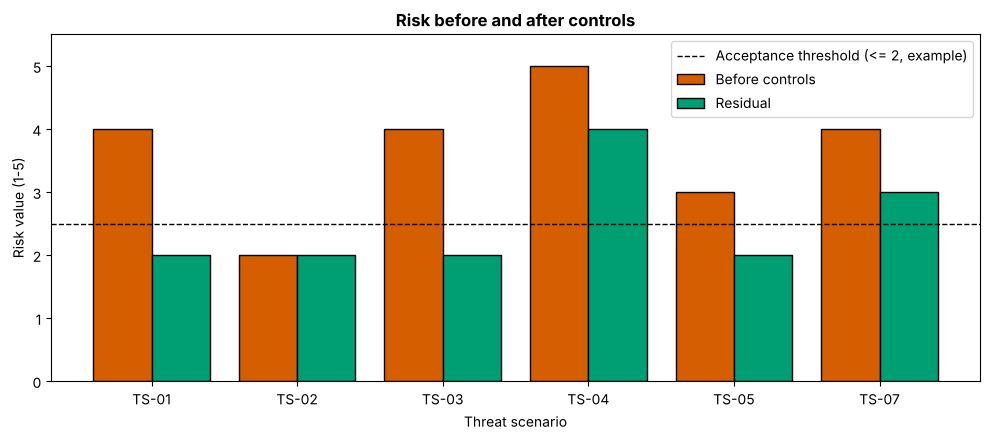

--- Residual risk (text summary) ---
  TS-01: risk 4 -> 2 (acceptable)
  TS-02: risk 2 -> 2 (acceptable)
  TS-03: risk 4 -> 2 (acceptable)
  TS-04: risk 5 -> 4 (further treatment or documented acceptance needed)
  TS-05: risk 3 -> 2 (acceptable)
  TS-07: risk 4 -> 3 (further treatment or documented acceptance needed)


In [12]:
controls = {
    'TS-01': {'controls': 'SecOC (AUTOSAR) with 128-bit CMAC truncated to 64 bit, freshness counter, keys in HSM; plausibility check in brake ECU',
              'floors': {'knowledge': 'strictly confidential', 'expertise': 'expert'}},
    'TS-02': {'controls': 'Signed packages verified before installation (ISO 24089 / UN R156 process), secure boot, signing keys in HSM',
              'floors': {}},
    'TS-03': {'controls': 'AEB intervention requires confirmation by the independent radar channel; perception plausibility monitor',
              'floors': {'elapsed_time': '<=6 months', 'expertise': 'multiple experts', 'equipment': 'bespoke'}},
    'TS-04': {'controls': 'Blinding/saturation detection with transition to degraded mode and driver warning',
              'damage': ['DS-03']},
    'TS-05': {'controls': 'UDS Authentication 0x29 (ISO 14229-1:2020, certificate-based, role-based write access) replaces seed/key 0x27',
              'floors': {'knowledge': 'strictly confidential'}},
    'TS-07': {'controls': 'AEB messages on a dedicated segment, not reachable from bumper-mounted connectors; bus-load monitoring',
              'floors': {'window': 'difficult'}},
}
ACCEPTABLE_RESIDUAL = 2   # example organisation policy

res = []
for r in threats[threats.Decision == 'Reduce'].to_dict('records'):
    c = controls[r['TS']]
    ds = c.get('damage', r['Damage scenarios'])
    impact = impact_of(ds)[0]
    _, agg, _ = rate_feasibility(r['TS'], c.get('floors'))
    risk = RISK_MATRIX[impact][agg['feasibility']]
    res.append({'TS': r['TS'], 'Controls': c['controls'], 'Risk before': r['Risk'],
                'Impact after': impact, 'Feasibility after': agg['feasibility'],
                'Attack potential after': agg['attack_potential'], 'Residual risk': risk,
                'Status': 'acceptable' if risk <= ACCEPTABLE_RESIDUAL else 'further treatment or documented acceptance needed'})
residual = pd.DataFrame(res)
display(residual[['TS', 'Risk before', 'Impact after', 'Attack potential after', 'Feasibility after', 'Residual risk', 'Status']])

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(residual))
ax.bar(x - 0.2, residual['Risk before'], 0.4, label='Before controls', color=OKABE_ITO[5], edgecolor='black')
ax.bar(x + 0.2, residual['Residual risk'], 0.4, label='Residual', color=OKABE_ITO[2], edgecolor='black')
ax.axhline(ACCEPTABLE_RESIDUAL + 0.5, ls='--', color='black', lw=1, label=f'Acceptance threshold (<= {ACCEPTABLE_RESIDUAL}, example)')
ax.set_xticks(x); ax.set_xticklabels(residual.TS)
ax.set_xlabel('Threat scenario'); ax.set_ylabel('Risk value (1-5)'); ax.set_ylim(0, 5.5)
ax.set_title('Risk before and after controls', fontweight='bold'); ax.legend(loc='upper right')
plt.tight_layout(); plt.show()
print('--- Residual risk (text summary) ---')
for r in residual.to_dict('records'):
    print(f"  {r['TS']}: risk {r['Risk before']} -> {r['Residual risk']} ({r['Status']})")

**Interpretation des Restrisikos.** Maßnahmen, die die Kosten eines Angriffs erhöhen, wirken gut gegen das Fälschen von Busbotschaften (TS-01) und den Missbrauch von Diagnosediensten (TS-05). **Physische Angriffe auf Sensoren verhalten sich anders.** Keine fahrzeugseitige Maßnahme verhindert, dass jemand mit einer Lichtquelle in eine Kamera leuchtet (TS-04). Das bestmögliche Ergebnis ist, *zu erkennen und sicher zu degradieren*. Das senkt die Auswirkung auf die Sicherheit, eine betriebliche Auswirkung bleibt aber. Solche Restrisiken werden typischerweise mit einem dokumentierten Claim akzeptiert oder durch die Architektur (Sensordiversität) weiter reduziert und im Feld beobachtet (Abschn. 8).

## 11. Durchgängige Rückverfolgbarkeit

Die folgende Tabelle wird aus der obigen Analyse erzeugt; nichts wird von Hand eingetragen. Sie ist die TARA-Sicht, der ein Reviewer oder Assessor (ISO/SAE PAS 5112) folgen würde: Sicherheitsziel → Schadensszenario → Bedrohungsszenario → Angriffspfad → Durchführbarkeit → Risiko → Behandlung → Ziel/Claim, CAL → Restrisiko.

In [13]:
trace = []
goal_by_ts = goals.set_index('TS')
resid_by_ts = residual.set_index('TS')['Residual risk']
for r in threats.to_dict('records'):
    g = goal_by_ts.loc[r['TS']]
    resid = int(resid_by_ts.get(r['TS'], r['Risk']))
    for ds in r['Damage scenarios']:
        trace.append({'SG': ds_index.loc[ds, 'Safety goal'], 'DS': ds, 'TS': r['TS'],
                      'Asset/property': f"{r['Asset']}/{r['Property']}", 'Path': r['Most feasible path'],
                      'AP': r['Attack potential'], 'Feasibility': r['Feasibility'], 'Impact': r['Impact'],
                      'Risk': r['Risk'], 'Decision': r['Decision'], 'Goal/claim': g['ID'], 'CAL': g['CAL'], 'Residual': resid})
trace = pd.DataFrame(trace).sort_values(['SG', 'DS', 'TS'])
display(trace)
assert trace.TS.nunique() == len(threats)
print('--- Traceability (text summary) ---')
for r in trace.to_dict('records'):
    print(f"  {r['SG']} <- {r['DS']} <- {r['TS']} ({r['Asset/property']}) via {r['Path']} [AP {r['AP']}, {r['Feasibility']}] "
          f"-> risk {r['Risk']} -> {r['Decision']} -> {r['Goal/claim']} ({r['CAL']}) -> residual {r['Residual']}")

,SG,DS,TS,Asset/property,Path,AP,Feasibility,Impact,Risk,Decision,Goal/claim,CAL,Residual
4,-,DS-03,TS-04,A-01/Availability,AP-04a,7,High,Severe,5,Reduce,CG-04,CAL 2,4
7,-,DS-03,TS-07,A-03/Availability,AP-07a,11,High,Major,4,Reduce,CG-07,CAL 1,3
6,-,DS-04,TS-06,A-06/Confidentiality,AP-06a,21,Low,Major,2,Retain,CC-06,n/a,2
0,SG-01,DS-01,TS-01,A-03/Integrity,AP-01b,15,Medium,Severe,4,Reduce,CG-01,CAL 4,2
1,SG-02,DS-02,TS-02,A-02/Integrity,AP-02b,41,Very Low,Severe,2,Reduce,CG-02,CAL 4,2
2,SG-02,DS-02,TS-03,A-03/Integrity,AP-03a,14,Medium,Severe,4,Reduce,CG-03,CAL 2,2
3,SG-02,DS-02,TS-04,A-01/Availability,AP-04a,7,High,Severe,5,Reduce,CG-04,CAL 2,4
5,SG-02,DS-02,TS-05,A-05/Integrity,AP-05a,21,Low,Severe,3,Reduce,CG-05,CAL 3,2


--- Traceability (text summary) ---
  - <- DS-03 <- TS-04 (A-01/Availability) via AP-04a [AP 7, High] -> risk 5 -> Reduce -> CG-04 (CAL 2) -> residual 4
  - <- DS-03 <- TS-07 (A-03/Availability) via AP-07a [AP 11, High] -> risk 4 -> Reduce -> CG-07 (CAL 1) -> residual 3
  - <- DS-04 <- TS-06 (A-06/Confidentiality) via AP-06a [AP 21, Low] -> risk 2 -> Retain -> CC-06 (n/a) -> residual 2
  SG-01 <- DS-01 <- TS-01 (A-03/Integrity) via AP-01b [AP 15, Medium] -> risk 4 -> Reduce -> CG-01 (CAL 4) -> residual 2
  SG-02 <- DS-02 <- TS-02 (A-02/Integrity) via AP-02b [AP 41, Very Low] -> risk 2 -> Reduce -> CG-02 (CAL 4) -> residual 2
  SG-02 <- DS-02 <- TS-03 (A-03/Integrity) via AP-03a [AP 14, Medium] -> risk 4 -> Reduce -> CG-03 (CAL 2) -> residual 2
  SG-02 <- DS-02 <- TS-04 (A-01/Availability) via AP-04a [AP 7, High] -> risk 5 -> Reduce -> CG-04 (CAL 2) -> residual 4
  SG-02 <- DS-02 <- TS-05 (A-05/Integrity) via AP-05a [AP 21, Low] -> risk 3 -> Reduce -> CG-05 (CAL 3) -> residual 2


## 12. Safety-Security-Co-Engineering

ISO 26262 und ISO/SAE 21434 bleiben getrennte Disziplinen mit getrennten Arbeitsprodukten, müssen aber Informationen austauschen. ISO 26262-2:2018 fordert Kommunikationswege zwischen funktionaler Sicherheit und Cybersicherheit; ihr informativer Anhang E beschreibt typische Wechselwirkungen. ISO/SAE 21434, Abschnitt 5, fordert dasselbe auf Organisationsebene.

1. **Gemeinsame Definition der Betrachtungseinheit.** Eine Definition, eine Grenze, ein Satz von Betriebsarten. In diesem Notebook beziehen sich beide Analysen auf dieselbe AEB-Betrachtungseinheit.
2. **Sicherheitsziele als Schadensszenarien.** Jedes TARA-Schadensszenario, das ein Sicherheitsziel verletzt, wird mit diesem verknüpft. Die Bedrohungsszenarien, die zu diesen Schadensszenarien führen, sind **Cybersicherheitsereignisse mit potenzieller Auswirkung auf die funktionale Sicherheit** und müssen dem Safety-Team mitgeteilt werden.
3. **Schutzmaßnahmen und Sicherheitsmechanismen.** Eine Security-Maßnahme, die in der Sicherheitsargumentation angerechnet wird (z. B. eine Plausibilisierung, die auch gefälschte Bremsanforderungen verwirft), muss die Sicherheitsanforderungen an Zeitverhalten, ASIL und Unabhängigkeit erfüllen. Umgekehrt gilt: Sicherheitsmechanismen wie E2E-Absicherung mit CRC und Zählern erkennen *zufällige* Verfälschung, halten aber einen Angreifer, der die CRC neu berechnen kann, **nicht** auf.
4. **Zeitverhalten.** Erkennung und Reaktion einer Security-Maßnahme müssen in das **FTTI** des Sicherheitsziels passen, wenn die Maßnahme zur sicheren Fahrzeugführung beiträgt. Kryptografische Prüfungen können auch Botschaftsverluste *verursachen*, z. B. nach dem Verlust der Freshness-Synchronisation. Dieser Botschaftsverlust muss vom Sicherheitskonzept abgedeckt sein.
5. **Keine Etiketten-Arithmetik.** ASIL und CAL werden unabhängig voneinander abgeleitet und lassen sich nicht aufeinander abbilden. Eine Anforderung kann sowohl einen ASIL als auch einen CAL tragen, aber „ASIL D + CAL 3“ ist für sich genommen keine Anforderung.

In [14]:
# (a) Cybersecurity events with potential safety impact, derived from the traceability table
safety_relevant = trace[trace.SG != '-'].groupby('SG').agg(
    threat_scenarios=('TS', lambda s: ', '.join(sorted(set(s)))),
    max_risk=('Risk', 'max'), max_residual=('Residual', 'max')).reset_index()
safety_relevant = safety_relevant.merge(safety_goals[['SG', 'Safety goal', 'ASIL', 'FTTI_ms']], on='SG')
display(safety_relevant)
for r in safety_relevant.to_dict('records'):
    print(f"{r['SG']} (ASIL {r['ASIL']}) can be violated by: {r['threat_scenarios']} "
          f"(max risk {r['max_risk']}, max residual {r['max_residual']}) -> communicate to the safety team")

# (b) Timing of security controls against the FTTI (illustrative values)
CAN_PERIOD_MS, CAMERA_PERIOD_MS = 20, 33
timing = pd.DataFrame([
    ('SecOC rejects a forged brake request', 'SG-01', 0.1, 0.0, True),
    ('Freshness loss -> valid frames dropped -> brake-ECU timeout (3 frames) -> degraded', 'SG-02', 3 * CAN_PERIOD_MS, 50.0, True),
    ('On-board timing IDS needs 5 anomalous frames, then ignores the sender', 'SG-01', 5 * CAN_PERIOD_MS, 50.0, False),
    ('Camera blinding detection (3 frames) -> degraded mode', 'SG-02', 3 * CAMERA_PERIOD_MS, 50.0, True),
    ('Backend VSOC detects attack, pushes countermeasure', 'SG-01', 3600e3, 0.0, False),
], columns=['Control', 'SG', 'Detection_ms', 'Reaction_ms', 'Acts before first malicious effect'])
timing = timing.merge(safety_goals[['SG', 'FTTI_ms']], on='SG')
timing['Total_ms'] = timing.Detection_ms + timing.Reaction_ms
timing['Within FTTI'] = timing.Total_ms <= timing.FTTI_ms
timing['Usable as safety mechanism'] = timing['Within FTTI'] & timing['Acts before first malicious effect']
display(timing)
print('--- Timing check (text summary) ---')
for r in timing.to_dict('records'):
    print(f"  {r['Control']}: {r['Total_ms']:.1f} ms vs FTTI {r['FTTI_ms']} ms ({r['SG']}) -> "
          f"{'within' if r['Within FTTI'] else 'exceeds'} FTTI; usable as safety mechanism: {r['Usable as safety mechanism']}")

,SG,threat_scenarios,max_risk,max_residual,Safety goal,ASIL,FTTI_ms
0,SG-01,TS-01,4,2,Avoid unintended AEB deceleration,D,300
1,SG-02,"TS-02, TS-03, TS-04, TS-05",5,4,Avoid omission of AEB deceleration when a collision with a pedestrian or a s...,B,500


SG-01 (ASIL D) can be violated by: TS-01 (max risk 4, max residual 2) -> communicate to the safety team
SG-02 (ASIL B) can be violated by: TS-02, TS-03, TS-04, TS-05 (max risk 5, max residual 4) -> communicate to the safety team


,Control,SG,Detection_ms,Reaction_ms,Acts before first malicious effect,FTTI_ms,Total_ms,Within FTTI,Usable as safety mechanism
0,SecOC rejects a forged brake request,SG-01,0.1,0.0,True,300,0.1,True,True
1,Freshness loss -> valid frames dropped -> brake-ECU timeout (3 frames) -> de...,SG-02,60.0,50.0,True,500,110.0,True,True
2,"On-board timing IDS needs 5 anomalous frames, then ignores the sender",SG-01,100.0,50.0,False,300,150.0,True,False
3,Camera blinding detection (3 frames) -> degraded mode,SG-02,99.0,50.0,True,500,149.0,True,True
4,"Backend VSOC detects attack, pushes countermeasure",SG-01,3600000.0,0.0,False,300,3600000.0,False,False


--- Timing check (text summary) ---
  SecOC rejects a forged brake request: 0.1 ms vs FTTI 300 ms (SG-01) -> within FTTI; usable as safety mechanism: True
  Freshness loss -> valid frames dropped -> brake-ECU timeout (3 frames) -> degraded: 110.0 ms vs FTTI 500 ms (SG-02) -> within FTTI; usable as safety mechanism: True
  On-board timing IDS needs 5 anomalous frames, then ignores the sender: 150.0 ms vs FTTI 300 ms (SG-01) -> within FTTI; usable as safety mechanism: False
  Camera blinding detection (3 frames) -> degraded mode: 149.0 ms vs FTTI 500 ms (SG-02) -> within FTTI; usable as safety mechanism: True
  Backend VSOC detects attack, pushes countermeasure: 3600000.0 ms vs FTTI 300 ms (SG-01) -> exceeds FTTI; usable as safety mechanism: False


**Interpretation der Zeitprüfung.** Das Backend-VSOC (Vehicle Security Operations Center) ist für die Reaktion auf Flottenebene unverzichtbar (Abschn. 8, 13), arbeitet aber im Stundenbereich. Es ist kein Sicherheitsmechanismus. Ein fahrzeugseitiges IDS, das erst nach mehreren Botschaften alarmiert, lässt die ersten gefälschten Botschaften durch. Es mag in das FTTI passen, verhindert das gefährliche Ereignis allein aber nicht. Es braucht einen vorbeugenden Partner wie SecOC oder eine Plausibilisierung. Notebook 4 baut ein solches IDS: [Angriffserkennung auf dem CAN-Bus](../../05_Cybersecurity_ISO21434/04_can_bus_intrusion_detection.ipynb) (engl.).

## 13. Übung: Ihre eigene TARA für V2X

Führen Sie eine TARA für einen V2X-Empfänger durch, der Objekte der kooperativen Wahrnehmung (z. B. ETSI CPM/DENM) in dieselbe AEB-Funktion einspeist. Nutzen Sie die Hilfsfunktionen oben. Eine Bedrohung ist bereits eingetragen. Ergänzen Sie mindestens drei weitere, zum Beispiel:
1. GNSS-Spoofing, das die Eigenposition verfälscht, mit der V2X-Objekte zugeordnet werden;
2. Wiedereinspielen (Replay) einer alten, gültig signierten Gefahrenwarnung;
3. ein sich fehlverhaltendes Gerät eines Innentäters mit gültigem Pseudonym-Zertifikat (Sybil-Angriff);
4. Störung des Funkkanals (Jamming; Verfügbarkeit).

Hinweise: V2X-Nachrichten sind **signiert, nicht verschlüsselt** (IEEE 1609.2 / ETSI TS 103 097). Die PKI ist in den USA das SCMS, in Europa das EU C-ITS CCMS (ETSI TS 102 940/941). Hintergrund: [Kooperatives Fahren mit V2X](../../07_Runtime_Assurance_and_Operations/04_v2x_cooperative_driving.ipynb) (engl.).

In [15]:
# Exercise scaffold: extend the lists, then re-run.
v2x_paths = {
    'TS-V01': {'AP-V01a': [step('Extract a pseudonym certificate key from a purchased aftermarket OBU', '<=6 months', 'expert', 'restricted', 'unlimited', 'specialized', 'Physical'),
                           step('Broadcast a forged "pedestrian on road" message within radio range', '<=1 day', 'proficient', 'public', 'easy', 'specialized')],
               'AP-V01b': [step('Spoof a message without a valid certificate (rejected by signature check)', '<=6 months', 'multiple experts', 'strictly confidential', 'easy', 'bespoke', 'Adjacent')]},
    # 'TS-V02': {...},  # TODO: your threat scenarios
}
v2x_impact = {'TS-V01': 'Severe'}   # DS: unintended emergency braking (as DS-01, S3 -> Severe); TODO: rate your own

for ts, paths in v2x_paths.items():
    aggs = {ap: aggregate_and(s) for ap, s in paths.items()}
    best = min(aggs, key=lambda k: aggs[k]['attack_potential'])
    remote = max((a['vector'] for a in aggs.values()), key=VECTORS.index)
    f = aggs[best]['feasibility']
    print(f"{ts}: best path {best} (AP {aggs[best]['attack_potential']}, {f}), impact {v2x_impact[ts]}, "
          f"risk {RISK_MATRIX[v2x_impact[ts]][f]}, CAL if reduced: {determine_cal(v2x_impact[ts], remote)} ({remote})")

TS-V01: best path AP-V01a (AP 31, Very Low), impact Severe, risk 2, CAL if reduced: 4 (Adjacent)


## 13. Üben mit automatischer Rückmeldung (automatisch geprüft)

Ersetzen Sie jedes `None` durch Ihre Antwort und führen Sie die Zelle erneut aus. Bis dahin meldet die Prüfung, dass noch keine Antwort vorliegt; bei einer falschen Antwort erhalten Sie einen Hinweis und einen Verweis auf den Abschnitt, der den Schritt erklärt. (Die Rückmeldungen sind englisch.)

Ein zweiter Pfad, die V2X-Warnung zu fälschen (TS-V01), hat zwei Schritte: (1) ein Entwicklungskit für Straßenrandeinheiten (RSU) kaufen und seine Schnittstelle erlernen (≤ 1 Woche, kundig, öffentlich, unbegrenzt, spezialisiert); (2) den Nachrichtenfahrplan der Kreuzung ermitteln und in Reichweite senden (≤ 1 Monat, Laie, eingeschränkt, leicht, Standard). Der Einstiegsvektor ist *Adjacent* (benachbart); das Schadensszenario ist **Severe** (schwerwiegend).

1. Aggregieren Sie den Pfad nach der Konvention aus Abschnitt 7 und geben Sie Angriffspotenzial und Durchführbarkeit an.
2. Geben Sie den Risikowert an. 3. Geben Sie den CAL des Ziels an, falls das Risiko reduziert wird.

In [16]:
# Auto-checked exercises: the checkers compute the reference answer with the course toolkit (avsafety)
# and give a hint when an answer is wrong. Installs the toolkit automatically on Colab.
try:
    from avsafety import exercises as ex
except ImportError:
    %pip install -q "avsafety @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    from avsafety import exercises as ex

In [17]:
path = [step("Buy an RSU development kit and learn its interface", "<=1 week", "proficient", "public", "unlimited",
             "specialized", "Adjacent"),
        step("Find the message schedule and transmit in range", "<=1 month", "layman", "restricted", "easy", "standard")]
agg = aggregate_and(path)                     # factor-wise maximum, as in section 7
labels = [next(k for k, v in FACTORS[f].items() if v == agg[f]) for f in FACTORS]

my_potential, my_feasibility = None, None
my_risk = None
my_cal = None

print(ex.check_attack_feasibility((my_potential, my_feasibility), *labels, exercise="1 path feasibility",
                                  see="sections 7 and 8"))
print(ex.check_risk_value(my_risk, "Severe", agg["feasibility"], exercise="2 risk value", see="section 9"))
print(ex.check_cal(my_cal, "Severe", "Adjacent", exercise="3 CAL", see="section 10"))

○ 1 path feasibility: no answer yet. Fill in your answer and run the check again.
○ 2 risk value: no answer yet. Fill in your answer and run the check again.
○ 3 CAL: no answer yet. Fill in your answer and run the check again.


## In der Industrie

**Arbeitsprodukte.** Die Ergebnisse aus Abschnitt 15 (Assets und Schadensszenarien, Bedrohungsszenarien, Auswirkungsbewertungen, Angriffspfade, Bewertungen der Angriffsdurchführbarkeit, Risikowerte, Entscheidungen zur Risikobehandlung), zusammengefasst im TARA-Bericht; die Cybersicherheitsziele, Claims und das Cybersicherheitskonzept (Abschnitt 9); sowie deren Verifikationsberichte. Für die Typgenehmigung nach UN R155 muss der Hersteller zeigen, dass die Risiken der Bedrohungen aus Anhang 5 für den Fahrzeugtyp bewertet und gemindert wurden.

**Verantwortung.** Ein Security-Architekt oder TARA-Analyst führt die Analyse in Workshops mit Funktions-, E/E-Architektur- und Safety-Ingenieuren durch; der Cybersecurity-Manager des Projekts genehmigt die Behandlungsentscheidungen und zeichnet die Cybersecurity Claims für beibehaltene Risiken ab.

**Werkzeuge und Formate.** Modellbasierte TARA-Werkzeuge, die Assets aus dem E/E-Architekturmodell ableiten, oder gelenkte Tabellenkalkulationen; Angriffsbäume je Bedrohungsszenario; Bedrohungskataloge (UN R155 Anhang 5, STRIDE) als Vollständigkeitsprüfung; eine schriftliche, vor der Analyse festgelegte Bewertungsmethode (welcher Ansatz aus Anhang G, welche Risikomatrix, welche Akzeptanzschwellen).

**Typische Review-Befunde**
- Auswirkung aus Herstellersicht (Gewährleistung, Marke) statt aus Sicht des Verkehrsteilnehmers bewertet; Auswirkung auf die Sicherheit nicht mit der G&R verknüpft.
- Durchführbarkeit als einzelnes Etikett ohne Begründung je Faktor angegeben; ähnliche Bedrohungen uneinheitlich bewertet.
- Schlüssel, Kalibrierdaten und Diagnosedienste fehlen in der Asset-Liste.
- Beibehaltene Risiken ohne Cybersecurity Claim; CAL so verwendet, als wäre er ein Risikowert.
- TARA nach Architekturänderungen oder neu veröffentlichten Schwachstellen nicht aktualisiert (Auslöser nach Abschnitt 8).

**Was ein Assessor prüft:** die Kette 15.3 → 15.9 für jedes Bedrohungsszenario rückverfolgbar (wie in Abschnitt 11); Abdeckung der Bedrohungen aus R155 Anhang 5; Bewertungsmethode vor der Anwendung dokumentiert; jedes Risiko oberhalb der Akzeptanzschwelle durch ein Ziel mit verifizierten Schutzmaßnahmen reduziert; sicherheitsrelevante Bedrohungsszenarien an das Safety-Team kommuniziert.

## Kernaussagen

1. **Sieben Schritte, feste Reihenfolge:** Assets & Schadensszenarien → Bedrohungsszenarien → Auswirkung → Angriffspfade → Durchführbarkeit → Risikowert → Behandlung.
2. **Bedrohungsszenario = Asset + Eigenschaft + Ursache**, verknüpft mit Schadensszenarien, die aus Sicht des Verkehrsteilnehmers bewertet werden.
3. **Angriffspfade machen die Durchführbarkeit überprüfbar.** Wählen Sie eine Aggregationskonvention (hier: UND = faktorweises Maximum, ODER = am leichtesten durchführbarer Pfad) und dokumentieren Sie sie.
4. **Ein Angriffspotenzial von 0–13 bedeutet hohe Durchführbarkeit.** Der Risikowert ergibt sich aus der Beispielmatrix (1–5).
5. **Jedes Bedrohungsszenario erhält eine Behandlungsentscheidung.** Reduzieren führt zu einem Cybersicherheitsziel mit CAL; Beibehalten oder Teilen führt zu einem Cybersecurity Claim.
6. Der **CAL** folgt aus Auswirkung und Angriffsvektor (Anhang E, informativ). Er ist weder Risikowert noch ASIL.
7. Das **Restrisiko** zeigt, welche Schutzmaßnahmen tatsächlich wirken. Physische Angriffe auf Sensoren lassen sich meist nur erkennen und durch Degradation beherrschen, nicht verhindern.
8. **Co-Engineering:** Definition der Betrachtungseinheit teilen, Schadensszenarien mit Sicherheitszielen verknüpfen und das Zeitverhalten von Security-Maßnahmen gegen das FTTI prüfen.

## Selbsttest

1. Nennen Sie die sieben TARA-Schritte mit ihren Unterabschnittsnummern.
2. Warum muss ein Bedrohungsszenario die Cybersicherheitseigenschaft benennen und nicht nur das Asset?
3. Ein Pfad hat Schritte mit (Zeit, Fachkenntnis, Kenntnis der Betrachtungseinheit, Gelegenheitsfenster, Ausrüstung) = (1, 3, 3, 4, 4) und (1, 3, 3, 0, 0). Wie groß sind das aggregierte Angriffspotenzial und die Durchführbarkeit nach der hier verwendeten Konvention?
4. Warum kann TS-04 (Blendung der Kamera) Risiko 5, aber nur CAL 2 haben?
5. Was ist der Unterschied zwischen einem Cybersicherheitsziel und einem Cybersecurity Claim?
6. Warum ist ein Backend-VSOC kein Sicherheitsmechanismus für SG-01?
7. Schützt E2E-Absicherung (CRC + Alive-Counter) vor gefälschten Botschaften? Warum (nicht)?

<details>
<summary>Antworten</summary>

1. 15.3 Assets & Schadensszenarien, 15.4 Bedrohungsszenarien, 15.5 Auswirkungsbewertung, 15.6 Angriffspfadanalyse, 15.7 Bewertung der Angriffsdurchführbarkeit, 15.8 Bestimmung des Risikowerts, 15.9 Entscheidung zur Risikobehandlung.
2. Die Eigenschaft bestimmt sowohl den Schaden als auch die Schutzmaßnahmen. Ein Verlust der *Integrität* der Objektliste erfordert Authentifizierung oder Gegenprüfungen; ein Verlust der *Verfügbarkeit* erfordert Erkennung und Degradation.
3. Faktorweises Maximum (1, 3, 3, 4, 4) → 15 → **Medium**.
4. Das Risiko kombiniert die Auswirkung Severe mit hoher Durchführbarkeit. Das CAL-Beispiel verwendet Auswirkung × Angriffsvektor, und ein physischer Vektor mit Auswirkung Severe ergibt CAL 2.
5. Ein Ziel ist die Anforderung, ein Asset gegen ein Bedrohungsszenario zu schützen (Risiko *reduziert*). Ein Claim dokumentiert, warum ein beibehaltenes oder geteiltes Risiko akzeptabel ist.
6. Seine Zeit für Erkennung und Reaktion (Stunden) liegt weit über dem FTTI (Millisekunden), und es wirkt erst nach dem gefährlichen Ereignis.
7. Nein. CRC und Zähler sind nicht geheim; ein Angreifer kann gültige Werte berechnen. Nur ein schlüsselbasierter MAC (z. B. SecOC) liefert Authentizität.
</details>

## Literatur

- ISO/SAE 21434:2021, *Road vehicles — Cybersecurity engineering*, clauses 9 and 15, Annexes E, F, G, H.
- ISO 26262-3:2018, *Road vehicles — Functional safety — Part 3: Concept phase* (Table 4).
- ISO 26262-2:2018, *Part 2: Management of functional safety* (Annex E, interaction with cybersecurity).
- ISO/IEC 18045:2022, *Methodology for IT security evaluation* (attack-potential factors).
- ISO 14229-1:2020, *Unified diagnostic services (UDS) — Part 1* (Authentication service 0x29).
- AUTOSAR, *Specification of Secure Onboard Communication* (SWS SecOC), Classic Platform R22-11 or later. https://www.autosar.org
- Shostack, A. (2014). *Threat Modeling: Designing for Security*. Wiley (STRIDE).
- Patel, M., Jung, R. (2026). Integrating Cybersecurity Into the AI Safety Assurance Argument: A GSN Pattern for AI-Based Perception Components in Highly Automated Driving. In *Computer Safety, Reliability, and Security. SAFECOMP 2026 Workshops*, LNCS, pp. 763–779. Springer. https://doi.org/10.1007/978-3-032-35506-5_55

## Weiterführende Übungen

- Begleitende Workshop-Übung: [TARA exercise](https://github.com/milinpatel07/AI-Perception-Safety-Workshop/blob/main/notebooks/10_tara_exercise.ipynb) (AI Perception Safety Workshop, engl.).
- Zu diesem Notebook passende Vorlage für die Praxis: [TARA-Vorlage](../../templates/TARA_Template.md) (engl.).

---
**Navigation:** ← [Zurück: SOTIF-Grundlagen](../04_SOTIF_ISO21448/01_sotif_fundamentals.ipynb) · [Englisches Original](../../05_Cybersecurity_ISO21434/02_tara.ipynb) · [Übersicht der Deutschen Ausgabe](../README.md) · [Weiter: KI-Sicherheitsnormen](../06_AI_Safety_ISO_PAS_8800/01_ai_safety_standards.ipynb) →